# 03 KAUH positive controls and recording screening

Frozen official-split models applied to KAUH 8 s windows (three vendor filters of the same recordings). A: prediction
invariance across filters (flip rate, TV distance). B2: conformal coverage, calibrate on one filter, test on another.
Screening: ICBHI-calibrated 2-class conformal triage applied per KAUH filter. Figures: `outputs/figures/kauh_screening/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/common.py
sys.path.insert(0, str(Path.cwd().parent))   # repository root for src.*
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from common import *
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
from src.evaluation.kauh import invariance, load as kload
FIG, TAB = out_dirs('kauh_screening')
KAUH = {'target-20261027': REPO / 'outputs/kauh/target-20261027', 'distill-20261028': REPO / 'outputs/kauh/distill-20261028'}
conds = {}
for camp, root in KAUH.items():
    for d in sorted(p for p in root.iterdir() if p.is_dir()):
        if d.name not in conds and list(d.glob('seed*.npz')):
            conds[d.name] = d
print(list(conds))

['anchor', 'class_aware_light', 'frozen', 'lora', 'lora_class_aware', 'multiscale', 'pcsl5_control', 'swa', 'kd_g4_k1', 'kd_g4_k2', 'kd_g7_k2']


## 1. Invariance across filters (A), per seed

flip              tv          
                   mean       std  mean       std
condition                                        
lora               0.04  9.64e-03  0.06  3.71e-03
lora_class_aware   0.07  3.73e-02  0.09  1.23e-02
class_aware_light  0.19  4.61e-02  0.14  2.01e-02
kd_g7_k2           0.19  4.27e-02  0.15  2.80e-02
swa                0.20  2.90e-02  0.19  2.47e-02
anchor             0.20  3.74e-02  0.20  3.63e-02
frozen             0.21  2.71e-02  0.21  2.47e-02
pcsl5_control      0.21  1.97e-02  0.21  2.32e-02
kd_g4_k2           0.21  4.39e-02  0.19  3.91e-02
kd_g4_k1           0.23  5.58e-02  0.19  4.04e-02
multiscale         0.24  3.28e-02  0.23  3.19e-02

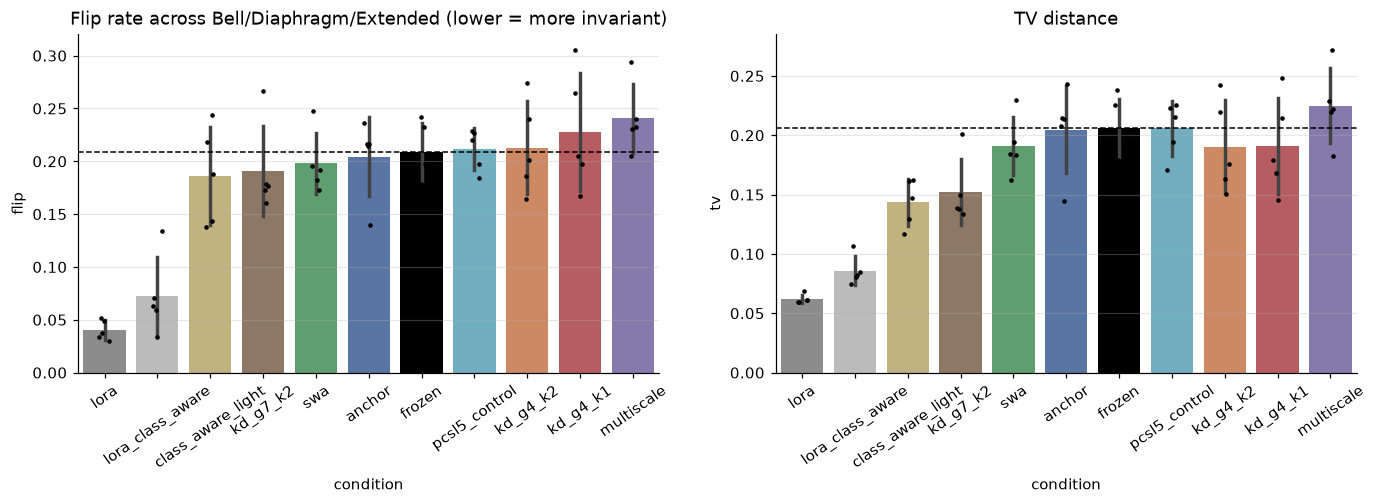

In [2]:
rows = []
for c, d in conds.items():
    for f in sorted(d.glob('seed*.npz')):
        fr, tv = invariance(kload(f))[:2]
        rows.append(dict(condition=c, seed=int(f.stem[4:]), flip=fr, tv=tv))
A = pd.DataFrame(rows); A.to_csv(TAB / 'kauh_invariance_per_seed.csv', index=False)
order = A.groupby('condition').flip.mean().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for i, m in enumerate(['flip', 'tv']):
    sns.barplot(data=A, x='condition', y=m, order=order, palette=[PALETTE.get(o, '#999') for o in order], errorbar='sd', ax=ax[i])
    sns.stripplot(data=A, x='condition', y=m, order=order, color='k', size=3, ax=ax[i])
    ax[i].axhline(A[A.condition == 'frozen'][m].mean(), color='k', ls='--', lw=1); ax[i].tick_params(axis='x', rotation=35)
ax[0].set_title('Flip rate across Bell/Diaphragm/Extended (lower = more invariant)'); ax[1].set_title('TV distance')
savefig(fig, FIG, 'kauh_invariance')
A.groupby('condition')[['flip', 'tv']].agg(['mean', 'std']).loc[order]

## 2. Bootstrap contrasts and B2 (from the saved summaries)

In [3]:
for camp, root in KAUH.items():
    print(f'### {camp}')
    print((root / 'kauh_summary.md').read_text().split('## B2')[0].split('Flip-rate reduction')[1][:1200])

### target-20261027
 against the baseline (positive: arm is more invariant), 95% bootstrap interval over patients and seeds:

- frozen - anchor: +0.004 [-0.040, +0.045]
- frozen - pcsl5_control: -0.003 [-0.046, +0.046]
- frozen - class_aware_light: +0.023 [-0.043, +0.093]
- frozen - lora_class_aware: +0.137 [+0.076, +0.205]
- frozen - lora: +0.169 [+0.122, +0.216]
- frozen - swa: +0.011 [-0.038, +0.055]
- frozen - multiscale: -0.032 [-0.086, +0.018]


### distill-20261028
 against the baseline (positive: arm is more invariant), 95% bootstrap interval over patients and seeds:

- frozen - anchor: +0.004 [-0.040, +0.045]
- frozen - kd_g4_k1: -0.019 [-0.082, +0.038]
- frozen - kd_g4_k2: -0.004 [-0.055, +0.046]
- frozen - kd_g7_k2: +0.018 [-0.045, +0.068]




PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/kauh_screening/kauh_b2.png')

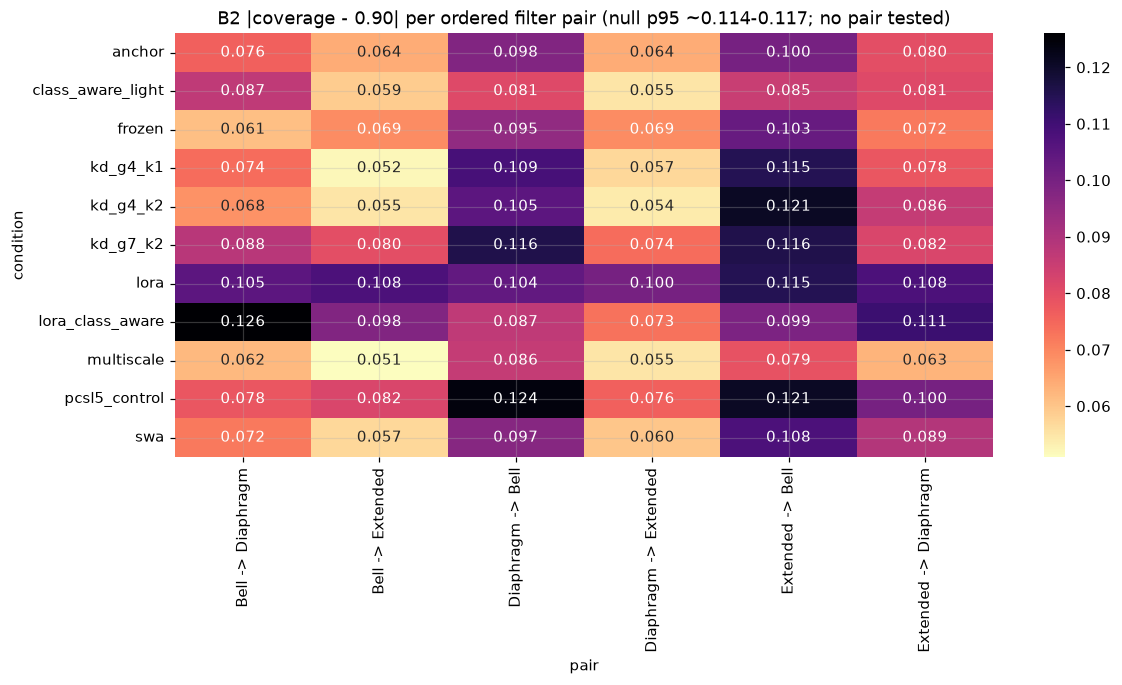

In [4]:
b2 = []
for camp, root in KAUH.items():
    txt = (root / 'kauh_summary.md').read_text().split('## B2')[1]
    for line in txt.splitlines():
        p = [x.strip() for x in line.strip('|').split('|')]
        if len(p) == 5 and '->' in p[0] and p[2][:1].isdigit():
            b2.append(dict(pair=p[0], condition=p[1], abs_delta=float(p[2]), null_p95=float(p[3])))
b2 = pd.DataFrame(b2).drop_duplicates(['pair', 'condition'])
b2.to_csv(TAB / 'kauh_b2.csv', index=False)
pv = b2.pivot(index='condition', columns='pair', values='abs_delta')
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(pv, annot=True, fmt='.3f', cmap='magma_r', ax=ax); ax.set_title('B2 |coverage - 0.90| per ordered filter pair (null p95 ~0.114-0.117; no pair tested)')
savefig(fig, FIG, 'kauh_b2')

## 3. Window probabilities per filter (anchor vs distilled K1)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/kauh_screening/kauh_prob_hist.png')

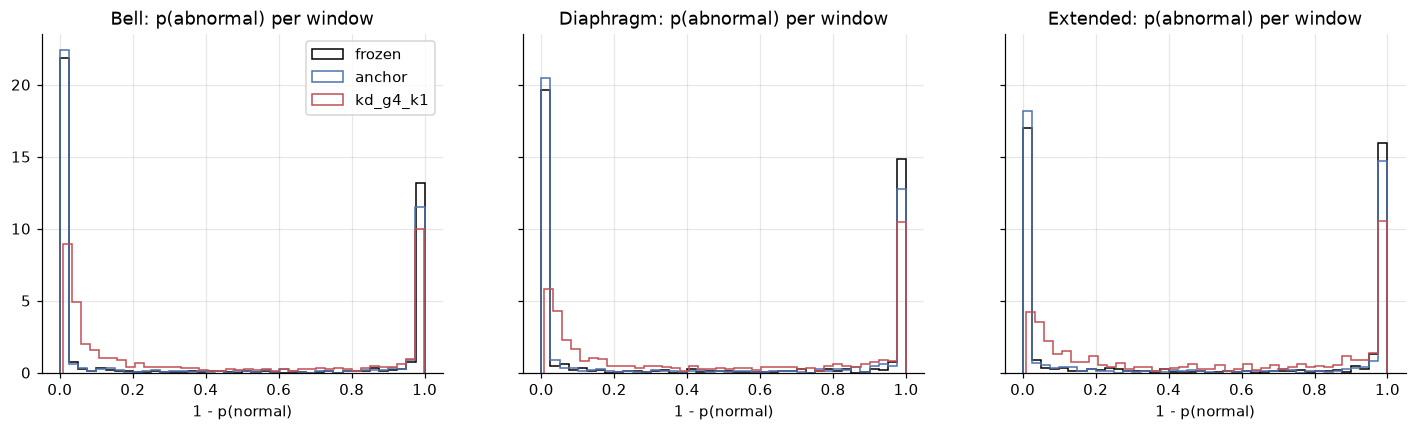

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for i, flt in enumerate(['Bell', 'Diaphragm', 'Extended']):
    for c in ['frozen', 'anchor', 'kd_g4_k1']:
        if c not in conds: continue
        z = [kload(f) for f in sorted(conds[c].glob('seed*.npz'))]
        pa = np.concatenate([1 - q['probs'][q['filter'] == flt][:, 0] for q in z])
        ax[i].hist(pa, bins=40, histtype='step', density=True, label=c, color=PALETTE.get(c, 'k'))
    ax[i].set_title(f'{flt}: p(abnormal) per window'); ax[i].set_xlabel('1 - p(normal)')
ax[0].legend()
savefig(fig, FIG, 'kauh_prob_hist')

## 4. Recording screening (ICBHI-calibrated conformal triage on KAUH)

coverage                                                    uncertain                                       
target            ICBHI evaluation half KAUH Bell KAUH Diaphragm KAUH Extended ICBHI evaluation half KAUH Bell KAUH Diaphragm KAUH Extended
condition                                                                                                                                  
anchor                             0.90      0.81           0.85          0.87                  0.56      0.47           0.51          0.53
class_aware_light                  0.91      0.94           0.94          0.96                  0.56      0.47           0.50          0.53
frozen                             0.90      0.83           0.86          0.88                  0.60      0.46           0.51          0.52
kd_g4_k1                           0.90      0.79           0.85          0.88                  0.53      0.31           0.36          0.39
kd_g4_k2                           0.91      0.80           0.85          0.88                  0.54      0.33           0.39          0.41
kd_g7_k2                           0.90      0.81           0.85          0.87                  0.53      0.35           0.38          0.40
lora                               0.91      0.90           0.87          0.89                  0.53      0.46           0.38          0.41
lora_class_aware                   0.91      0.93           0.89          0.91                  0.54      0.46           0.38          0.43
multiscale                         0.91      0.86           0.87          0.89                  0.61      0.55           0.51          0.53
pcsl5_control                      0.91      0.80           0.85          0.88                  0.61      0.39           0.43          0.46
swa                                0.91      0.81           0.85          0.88                  0.55      0.38           0.43          0.46

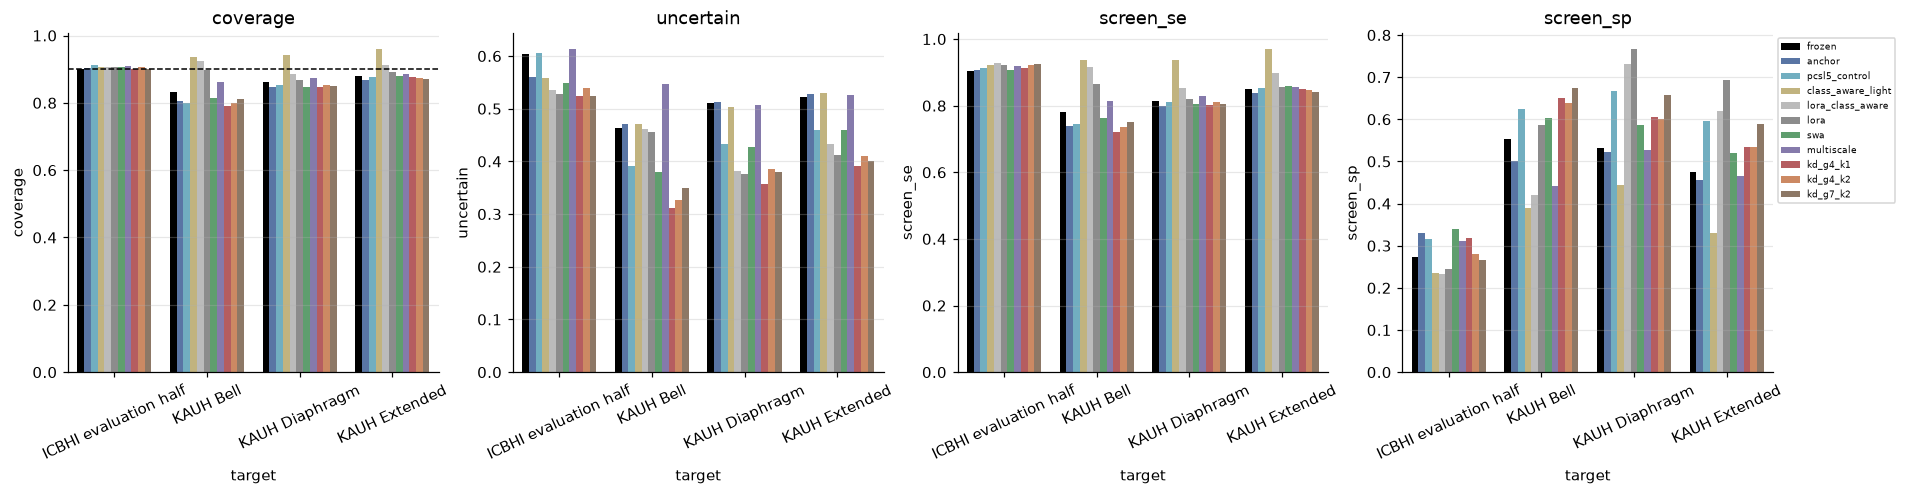

In [6]:
S = {}
for f in [REPO / 'outputs/screening/target-20261027/screening_summary.json', REPO / 'outputs/screening/distill-20261028/screening_summary.json']:
    S.update(json.loads(f.read_text()))
sc = pd.DataFrame([dict(condition=k.split('|')[0], target=k.split('|')[1].split(' (')[0], agg=k.split('|')[2], **v) for k, v in S.items()])
sc.to_csv(TAB / 'screening.csv', index=False)
m = sc[sc['agg'] == 'mean']
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i, k in enumerate(['coverage', 'uncertain', 'screen_se', 'screen_sp']):
    sns.barplot(data=m, x='target', y=k, hue='condition', ax=ax[i], palette=PALETTE)
    ax[i].tick_params(axis='x', rotation=25); ax[i].set_title(k); ax[i].get_legend().remove() if i < 3 else ax[i].legend(fontsize=6, bbox_to_anchor=(1, 1))
ax[0].axhline(0.9, color='k', ls='--', lw=1)
savefig(fig, FIG, 'screening_mean_agg')
m.pivot_table(index='condition', columns='target', values=['coverage', 'uncertain']).round(3)

## Notes

- [Fact] No B2 pair passes the null gate for any condition, so no coverage-shift (D) claim is made from KAUH.
- [Fact] LoRA arms reduce the flip rate but have the lowest official and LODO Scores.
- [Fact] The distilled students reduce the uncertain share on KAUH with slightly lower coverage; not paired-tested.